# Your first browser experiment

**Foundations · 15 minutes**

JupyterLite runs Python through Pyodide/WebAssembly in your browser. First load needs a network connection to fetch the runtime. Once loaded, these exercises read no external data; a fresh fully offline browser is not guaranteed to start.

Open a notebook, wait for **Python (Pyodide)**, and run with **Shift+Enter**. Restart the kernel and Run All to check reproducibility. Files and edits live in browser storage; download valuable work before clearing browser data or changing browser profiles. This index uses its own storage namespace.

**Question:** How does a threshold change the summary of an invented dataset?


## What can a browser workspace do?

JupyterLite provides a browser workspace for computation, authoring and exploration. Available packages, kernels and extensions depend on the site build. This atlas includes Python/Pyodide and small, self-contained examples; the linked courses extend the range.

| Possibility | What it enables | A useful boundary |
|---|---|---|
| Notebooks and interactive consoles | Explain a question, run code, inspect results and reproduce a calculation | Restart and Run All to check hidden state |
| Scientific Python | Work with compatible pure-Python and WebAssembly packages | Package compatibility, downloads and device memory matter |
| Files and rich documents | Edit code, Markdown and JSON; inspect tables; exchange small data files | Browser storage is local until you download or explicitly share files |
| Visual analytics | Combine charts, SVG, maps, widgets and dashboards | Widgets and map libraries may require matching extensions, network services and attribution |
| Geospatial workflows | Exchange GeoJSON, inspect STAC metadata, compare layers and explore time or terrain | Check units, coordinate systems, provenance, CORS and the meaning of missing data |
| AI and machine learning | Fit small models and inspect evidence or structured model requests | Large native/GPU stacks and credentialed services require their supported environment |
| Site customization | Package additional compatible kernels, extensions and learning materials | A feature in another deployment is not automatically installed here |

Try [fitting a model](learning-a-model.ipynb), [browser GIS](../projects/rustgis/index.ipynb), [visualization](../projects/data-visualization/index.ipynb), and [human-centered iteration](evidence-ai.ipynb).

**Sources:** [JupyterLite documentation](https://jupyterlite.readthedocs.io/en/stable/), [configuration and extensions](https://jupyterlite.readthedocs.io/en/stable/howto/configure/advanced/extensions.html), and [Pyodide package loading](https://pyodide.org/en/stable/usage/loading-packages.html). The original examples, package support and full source-course limits remain documented separately.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Synthetic observations: [2, 4, 4, 6, 9]
Mean: 5.0
Your first synthetic comparison | observations: {'below': 3, 'at or above': 2}


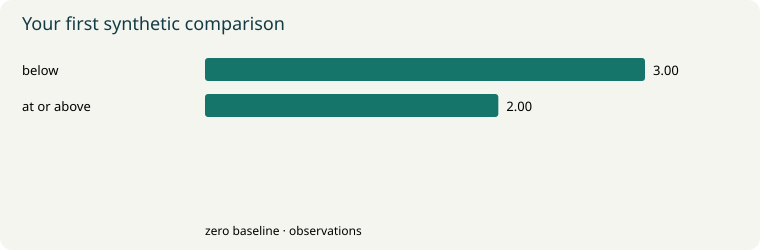

In [2]:
observations = [2,4,4,6,9]
threshold = 5
print('Synthetic observations:', observations)
print('Mean:', sum(observations)/len(observations))
bars({'below':sum(x<threshold for x in observations), 'at or above':sum(x>=threshold for x in observations)}, 'Your first synthetic comparison', 'observations')


## Interpret and try

Three invented observations are below 5 and two are at or above it. Change the threshold to 4 and predict the result before running. A programming error, a bad assumption and an unsupported interpretation are different problems.

If no kernel appears, allow runtime downloads, wait for startup, and reload once; use the static Book while troubleshooting. No package installation is needed inside these lessons. Do not upload sensitive records.

![Browser and continuation capabilities](../assets/capabilities.svg)

Original diagram, CC BY 4.0. [Provenance](../visual-provenance.ipynb).

**References:** [JupyterLite](https://jupyterlite.readthedocs.io/en/stable/) and [Pyodide](https://pyodide.org/en/stable/). Their runtime downloads and libraries retain their terms. [Next: 1854 Cholera Basic](../projects/cholera-1854-basic/index.ipynb) · [Spatial thinking](spatial-thinking.ipynb).
